In [1]:
import pandas as pd
import numpy as np

In [2]:
hourly_path = (
    "../data/raw/"
    "analysis/phase1/phase1_hourly_load_profile.csv"
)

hourly = pd.read_csv(hourly_path)

print(hourly.shape)
hourly.head()

(8760, 6)


,datetime,baseline_unweighted_kw,scenario_unweighted_kw,baseline_weighted_mw,scenario_weighted_mw,change_weighted_mw
0,01/01 01:00:00,1948.519777,3658.108515,494.736328,928.807187,434.070859
1,01/01 02:00:00,2040.054531,4096.614874,517.977338,1040.145562,522.168224
2,01/01 03:00:00,2098.861427,4436.065238,532.908625,1126.333256,593.424632
3,01/01 04:00:00,2151.238254,4582.300249,546.207293,1163.462863,617.255569
4,01/01 05:00:00,2245.736930,4842.214620,570.200854,1229.456076,659.255222


In [3]:
hourly["month"] = hourly["datetime"].str[:2].astype(int)

heat_months = [10, 11, 12, 1, 2, 3, 4]
cool_months = [6, 7, 8, 9]

resstock_annual_gwh = hourly["baseline_weighted_mw"].sum() / 1000

resstock_heat_gwh = (
    hourly.loc[
        hourly["month"].isin(heat_months),
        "baseline_weighted_mw"
    ].sum() / 1000
)

resstock_cool_gwh = (
    hourly.loc[
        hourly["month"].isin(cool_months),
        "baseline_weighted_mw"
    ].sum() / 1000
)

resstock_may_gwh = (
    hourly.loc[
        hourly["month"] == 5,
        "baseline_weighted_mw"
    ].sum() / 1000
)

resstock_ratio = resstock_heat_gwh / resstock_cool_gwh

print("ResStock annual:", round(resstock_annual_gwh, 2), "GWh")
print("ResStock Oct-Apr:", round(resstock_heat_gwh, 2), "GWh")
print("ResStock Jun-Sep:", round(resstock_cool_gwh, 2), "GWh")
print("ResStock May:", round(resstock_may_gwh, 2), "GWh")
print("ResStock heating/cooling ratio:", round(resstock_ratio, 3))

ResStock annual: 2444.93 GWh
ResStock Oct-Apr: 1568.66 GWh
ResStock Jun-Sep: 720.29 GWh
ResStock May: 155.98 GWh
ResStock heating/cooling ratio: 2.178


In [4]:
observed_annual_gwh = 1619.292
observed_heat_gwh = 925.436
observed_cool_gwh = 585.911
observed_may_gwh = 107.945
observed_ratio = observed_heat_gwh / observed_cool_gwh

comparison = pd.DataFrame({
    "Metric": [
        "Annual electricity",
        "Heating season Oct-Apr",
        "Cooling season Jun-Sep",
        "May shoulder month",
        "Heating/Cooling ratio"
    ],
    "Observed Suffolk 2018": [
        observed_annual_gwh,
        observed_heat_gwh,
        observed_cool_gwh,
        observed_may_gwh,
        observed_ratio
    ],
    "ResStock baseline": [
        resstock_annual_gwh,
        resstock_heat_gwh,
        resstock_cool_gwh,
        resstock_may_gwh,
        resstock_ratio
    ]
})

comparison["Percent difference"] = (
    (comparison["ResStock baseline"] - comparison["Observed Suffolk 2018"])
    / comparison["Observed Suffolk 2018"]
    * 100
)

comparison.round(2)

,Metric,Observed Suffolk 2018,ResStock baseline,Percent difference
0,Annual electricity,1619.29,2444.93,50.99
1,Heating season Oct-Apr,925.44,1568.66,69.50
2,Cooling season Jun-Sep,585.91,720.29,22.94
3,May shoulder month,107.94,155.98,44.50
4,Heating/Cooling ratio,1.58,2.18,37.88


In [5]:
# Observed 2018 Suffolk monthly residential electricity, GWh
observed_monthly = pd.Series({
    1: 165.282,
    2: 128.310,
    3: 133.469,
    4: 113.416,
    5: 107.945,
    6: 125.765,
    7: 165.519,
    8: 168.235,
    9: 126.392,
    10: 113.399,
    11: 127.086,
    12: 144.474
})

# ResStock monthly baseline electricity
resstock_monthly = (
    hourly.groupby("month")["baseline_weighted_mw"].sum()
    / 1000
)

monthly_comparison = pd.DataFrame({
    "Observed_GWh": observed_monthly,
    "ResStock_GWh": resstock_monthly
})

monthly_comparison["Percent_difference"] = (
    (monthly_comparison["ResStock_GWh"] - monthly_comparison["Observed_GWh"])
    / monthly_comparison["Observed_GWh"]
    * 100
)

monthly_comparison.round(2)

,Observed_GWh,ResStock_GWh,Percent_difference
1,165.28,306.95,85.71
2,128.31,223.53,74.21
3,133.47,244.83,83.43
4,113.42,190.74,68.17
5,107.94,155.98,44.50
6,125.76,157.84,25.51
7,165.52,198.77,20.09
8,168.24,200.83,19.37
9,126.39,162.85,28.85
10,113.40,161.96,42.83


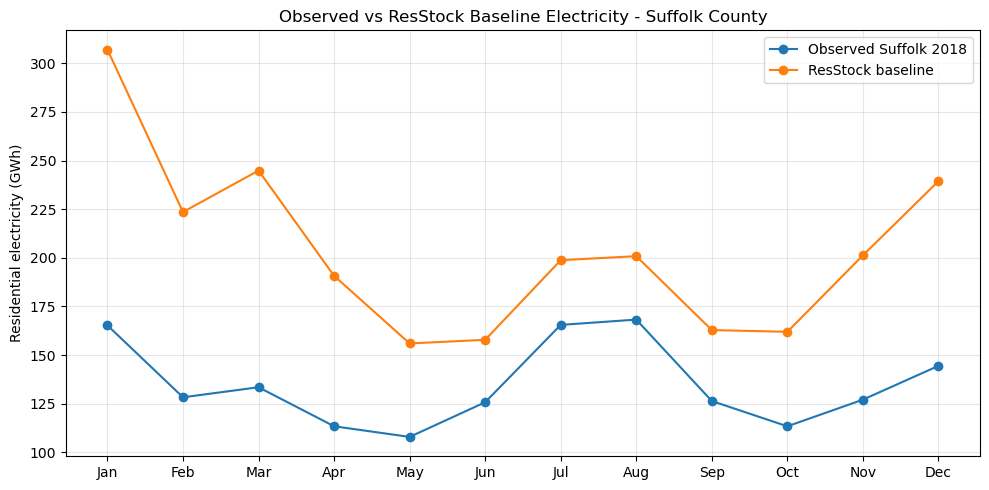

In [6]:
import matplotlib.pyplot as plt

months = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(10,5))

plt.plot(
    months,
    monthly_comparison["Observed_GWh"],
    marker="o",
    label="Observed Suffolk 2018"
)

plt.plot(
    months,
    monthly_comparison["ResStock_GWh"],
    marker="o",
    label="ResStock baseline"
)

plt.ylabel("Residential electricity (GWh)")
plt.title("Observed vs ResStock Baseline Electricity - Suffolk County")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

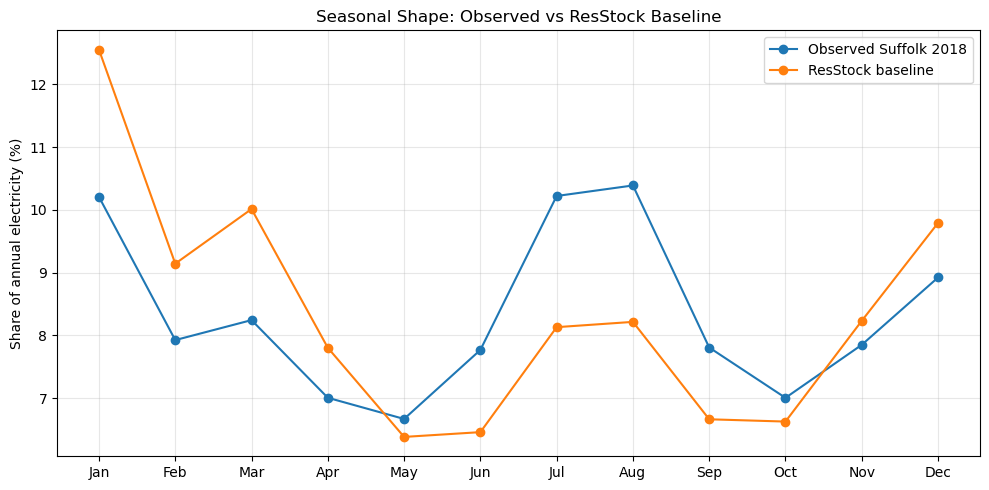

In [7]:
shape_comparison = monthly_comparison.copy()

shape_comparison["Observed_share"] = (
    shape_comparison["Observed_GWh"]
    / shape_comparison["Observed_GWh"].sum()
)

shape_comparison["ResStock_share"] = (
    shape_comparison["ResStock_GWh"]
    / shape_comparison["ResStock_GWh"].sum()
)

plt.figure(figsize=(10,5))

plt.plot(
    months,
    shape_comparison["Observed_share"] * 100,
    marker="o",
    label="Observed Suffolk 2018"
)

plt.plot(
    months,
    shape_comparison["ResStock_share"] * 100,
    marker="o",
    label="ResStock baseline"
)

plt.ylabel("Share of annual electricity (%)")
plt.title("Seasonal Shape: Observed vs ResStock Baseline")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
annual_total = 2444.93
heating_enduse = 552.36
cooling_enduse = 261.03

print("Heating share of annual electricity:",
      round(heating_enduse / annual_total * 100, 1), "%")

print("Cooling share of annual electricity:",
      round(cooling_enduse / annual_total * 100, 1), "%")

Heating share of annual electricity: 22.6 %
Cooling share of annual electricity: 10.7 %


In [9]:
up00_path = (
    "../data/raw/"
    "analysis/phase1/up00_building_summary.csv"
)

up00 = pd.read_csv(up00_path)

print(up00.shape)
up00.head()

(1330, 8)


,building_id,annual_electricity_kwh,winter_electricity_kwh,heating_electricity_kwh,cooling_electricity_kwh,natural_gas_kwh_eq,fuel_oil_kwh_eq,peak_15min_kw
0,bldg0001129-up00,9781.432426,3965.283687,0.000000,1346.580017,948.635886,29914.468808,7.613821
1,bldg0001702-up00,4241.133913,1883.118990,348.933217,663.775425,3904.339873,0.000000,12.367560
2,bldg0001785-up00,11871.338561,7905.585500,6819.740720,214.317193,0.000000,0.000000,8.675867
3,bldg0001942-up00,4056.556848,1595.688384,0.000000,441.885248,7777.492041,0.000000,5.129490
4,bldg0002069-up00,11869.894859,5772.741524,0.000000,530.792018,128616.720538,0.000000,4.277619


In [10]:
up00["heating_share"] = (
    up00["heating_electricity_kwh"] /
    up00["annual_electricity_kwh"]
)

up00[
    [
        "building_id",
        "annual_electricity_kwh",
        "heating_electricity_kwh",
        "cooling_electricity_kwh",
        "heating_share"
    ]
].sort_values("heating_share", ascending=False).head(20)

,building_id,annual_electricity_kwh,heating_electricity_kwh,cooling_electricity_kwh,heating_share
1155,bldg0476019-up00,4155.121695,3747.289509,0.000000,0.901848
96,bldg0043562-up00,19152.882528,16983.162569,0.000000,0.886716
573,bldg0249485-up00,6365.392498,5567.329672,0.000000,0.874625
463,bldg0196910-up00,6538.056933,5562.290826,250.888753,0.850756
833,bldg0351350-up00,5303.196238,4471.325120,263.080811,0.843138
361,bldg0155032-up00,21436.569141,17944.677525,0.000000,0.837106
327,bldg0144151-up00,7104.607605,5934.247000,395.200115,0.835267
923,bldg0386186-up00,3182.226976,2650.143993,110.381049,0.832795
206,bldg0097326-up00,20470.640934,16923.871370,0.000000,0.826739
1241,bldg0514258-up00,70708.951340,58337.351501,2430.252650,0.825035


In [11]:
up00["heating_share"].describe()

count    1330.000000
mean        0.120665
std         0.228071
min         0.000000
25%         0.000000
50%         0.000000
75%         0.094385
max         0.901848
Name: heating_share, dtype: float64

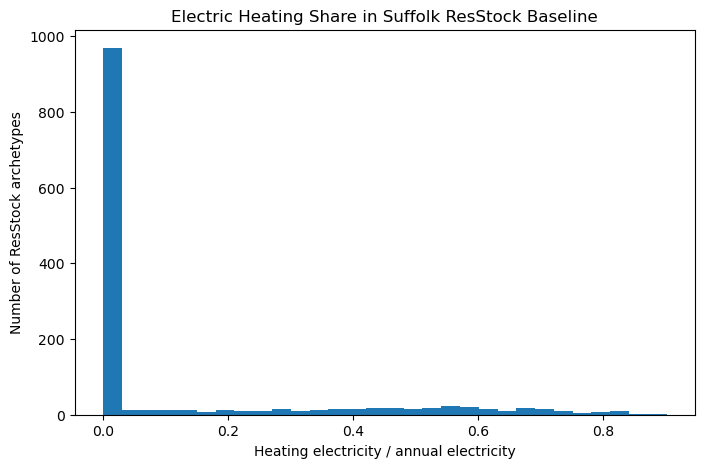

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(up00["heating_share"].dropna(), bins=30)
plt.xlabel("Heating electricity / annual electricity")
plt.ylabel("Number of ResStock archetypes")
plt.title("Electric Heating Share in Suffolk ResStock Baseline")
plt.show()

In [13]:
n_total = len(up00)
n_heating = (up00["heating_electricity_kwh"] > 0).sum()

print("Total archetypes:", n_total)
print("Archetypes with electric heating:", n_heating)
print(
    "Percent with electric heating:",
    round(n_heating / n_total * 100, 1),
    "%"
)

print(
    "Percent with >50% of electricity used for heating:",
    round((up00["heating_share"] > 0.50).mean() * 100, 1),
    "%"
)

Total archetypes: 1330
Archetypes with electric heating: 374
Percent with electric heating: 28.1 %
Percent with >50% of electricity used for heating: 12.0 %


In [14]:
heating_contributors = up00[
    up00["heating_electricity_kwh"] > 0
].copy()

heating_contributors["share_of_total_heating"] = (
    heating_contributors["heating_electricity_kwh"]
    / up00["heating_electricity_kwh"].sum()
)

heating_contributors = heating_contributors.sort_values(
    "heating_electricity_kwh",
    ascending=False
)

heating_contributors[
    [
        "building_id",
        "annual_electricity_kwh",
        "heating_electricity_kwh",
        "heating_share",
        "share_of_total_heating"
    ]
].head(20)

,building_id,annual_electricity_kwh,heating_electricity_kwh,heating_share,share_of_total_heating
1241,bldg0514258-up00,70708.951340,58337.351501,0.825035,0.026816
287,bldg0128909-up00,65392.751587,53693.880154,0.821098,0.024682
640,bldg0277408-up00,64425.099219,48733.784098,0.756441,0.022402
75,bldg0037308-up00,44207.818793,34621.269268,0.783148,0.015915
326,bldg0144078-up00,46499.132912,34324.495729,0.738175,0.015778
1002,bldg0419876-up00,40667.907320,32239.546445,0.792752,0.014820
934,bldg0391013-up00,36588.834011,28896.664178,0.789767,0.013283
675,bldg0291361-up00,35247.073528,26243.041104,0.744545,0.012063
1136,bldg0472448-up00,38445.318693,25726.968229,0.669183,0.011826
641,bldg0279395-up00,33510.764368,24435.580168,0.729186,0.011232


In [15]:
heating_contributors["cumulative_heating_share"] = (
    heating_contributors["share_of_total_heating"].cumsum()
)

heating_contributors[
    [
        "building_id",
        "heating_electricity_kwh",
        "heating_share",
        "share_of_total_heating",
        "cumulative_heating_share"
    ]
].head(30)

,building_id,heating_electricity_kwh,heating_share,share_of_total_heating,cumulative_heating_share
1241,bldg0514258-up00,58337.351501,0.825035,0.026816,0.026816
287,bldg0128909-up00,53693.880154,0.821098,0.024682,0.051498
640,bldg0277408-up00,48733.784098,0.756441,0.022402,0.073900
75,bldg0037308-up00,34621.269268,0.783148,0.015915,0.089814
326,bldg0144078-up00,34324.495729,0.738175,0.015778,0.105592
1002,bldg0419876-up00,32239.546445,0.792752,0.014820,0.120412
934,bldg0391013-up00,28896.664178,0.789767,0.013283,0.133695
675,bldg0291361-up00,26243.041104,0.744545,0.012063,0.145758
1136,bldg0472448-up00,25726.968229,0.669183,0.011826,0.157584
641,bldg0279395-up00,24435.580168,0.729186,0.011232,0.168817


In [16]:
total_heat = up00["heating_electricity_kwh"].sum()

for n in [10, 25, 50, 100]:
    share = (
        heating_contributors.head(n)["heating_electricity_kwh"].sum()
        / total_heat
        * 100
    )
    print(f"Top {n} archetypes contribute {share:.1f}% of heating electricity")

Top 10 archetypes contribute 16.9% of heating electricity
Top 25 archetypes contribute 28.6% of heating electricity
Top 50 archetypes contribute 42.8% of heating electricity
Top 100 archetypes contribute 63.8% of heating electricity


In [17]:
import os

search_roots = [
    "../data/raw/heatpumps",
    "../data/raw"
]

matches = []

for root in search_roots:
    for dirpath, dirnames, filenames in os.walk(root):
        # avoid enormous raw simulation-output trees
        if "output_files" in dirpath:
            continue

        for f in filenames:
            name = f.lower()

            if (
                ("meta" in name or "metadata" in name)
                and (name.endswith(".csv") or name.endswith(".parquet"))
            ):
                matches.append(os.path.join(dirpath, f))

matches[:100]

['/projectnb/climpct/gmbetts/heatpumps/data/merged_csv/hourly_outcome_with_ambtemp_metareduce_25025.csv']

In [18]:
import os

candidate_files = []

roots = [
    "../data/raw/heatpumps",
    "../data/raw"
]

for root in roots:
    for dirpath, dirnames, filenames in os.walk(root):
        # skip huge raw simulation outputs
        if "output_files" in dirpath:
            continue

        for f in filenames:
            name = f.lower()

            if name.endswith((".csv", ".parquet")):
                if any(k in name for k in [
                    "buildstock",
                    "building",
                    "stock",
                    "county",
                    "suffolk",
                    "upgrade00",
                    "up00"
                ]):
                    candidate_files.append(os.path.join(dirpath, f))

candidate_files[:100]

['/projectnb/climpct/astika10/heatpumps/analysis/phase2/up00_building_summary.csv',
 '/projectnb/climpct/astika10/heatpumps/analysis/phase2/up04_building_summary.csv',
 '/projectnb/climpct/astika10/heatpumps/analysis/phase1/up00_building_summary.csv',
 '/projectnb/climpct/astika10/heatpumps/analysis/phase1/up04_building_summary.csv',
 '/projectnb/climpct/gmbetts/heatpumps/data/metadata/upgrade00.csv',
 '/projectnb/climpct/gmbetts/heatpumps/data/merged_csv/merged_buildings.csv',
 '/projectnb/climpct/gmbetts/heatpumps/data/merged_csv/simulation outcome by building and upgrade/25/025/bldg0442953-up00_merged.csv',
 '/projectnb/climpct/gmbetts/heatpumps/data/merged_csv/simulation outcome by building and upgrade/25/025/bldg0248838-up00_merged.csv',
 '/projectnb/climpct/gmbetts/heatpumps/data/merged_csv/simulation outcome by building and upgrade/25/025/bldg0333762-up00_merged.csv',
 '/projectnb/climpct/gmbetts/heatpumps/data/merged_csv/simulation outcome by building and upgrade/25/025/bldg054

In [19]:
meta_path = "../data/raw/upgrade00.csv"  # ResStock metadata

meta = pd.read_csv(meta_path)

print("Shape:", meta.shape)
print("\nColumns:")
print(meta.columns.tolist())

meta.head()

Shape: (1330, 771)

Columns:
['bldg_id', 'completed_status', 'upgrade', 'in.upgrade_name', 'weight', 'applicability', 'in.sqft..ft2', 'in.representative_income', 'in.county_name', 'in.ahs_region', 'in.aiannh_area', 'in.area_median_income', 'in.ashrae_iecc_climate_zone_2004', 'in.ashrae_iecc_climate_zone_2004_sub_cz_split', 'in.bathroom_spot_vent_hour', 'in.battery', 'in.bedrooms', 'in.building_america_climate_zone', 'in.cec_climate_zone', 'in.ceiling_fan', 'in.census_division', 'in.census_division_recs', 'in.census_region', 'in.city', 'in.clothes_dryer', 'in.clothes_dryer_usage_level', 'in.clothes_washer', 'in.clothes_washer_presence', 'in.clothes_washer_usage_level', 'in.cooking_range', 'in.cooking_range_usage_level', 'in.cooling_unavailable_days', 'in.cooling_setpoint', 'in.cooling_setpoint_has_offset', 'in.cooling_setpoint_offset_magnitude', 'in.cooling_setpoint_offset_period', 'in.corridor', 'in.county', 'in.county_and_puma', 'in.county_metro_status', 'in.custom_state', 'in.dehumid

/scratch/8594154.1.geo-int/ipykernel_3829143/721040949.py:3: DtypeWarning: Columns (53,151,152) have mixed types. Specify dtype option on import or set low_memory=False.
  meta = pd.read_csv(meta_path)


,bldg_id,completed_status,upgrade,in.upgrade_name,weight,applicability,in.sqft..ft2,in.representative_income,in.county_name,in.ahs_region,...,calc.weighted.emissions_reduction.electricity.lrmer_high_re_cost_15..co2e_mmt,calc.weighted.emissions_reduction.electricity.lrmer_high_re_cost_25..co2e_mmt,calc.weighted.emissions_reduction.electricity.lrmer_high_re_cost_low_ng_price_15..co2e_mmt,calc.weighted.emissions_reduction.electricity.lrmer_high_re_cost_low_ng_price_25..co2e_mmt,calc.weighted.emissions_reduction.electricity.lrmer_low_re_cost_15..co2e_mmt,calc.weighted.emissions_reduction.electricity.lrmer_low_re_cost_25..co2e_mmt,calc.weighted.emissions_reduction.electricity.lrmer_low_re_cost_high_ng_price_15..co2e_mmt,calc.weighted.emissions_reduction.electricity.lrmer_low_re_cost_high_ng_price_25..co2e_mmt,calc.weighted.emissions_reduction.electricity.lrmer_mid_case_15..co2e_mmt,calc.weighted.emissions_reduction.electricity.lrmer_mid_case_25..co2e_mmt
0,1129,Success,0,Baseline,253.903673,True,1682,131826.0,Suffolk County,"CBSA Boston-Cambridge-Newton, MA-NH",...,0,0,0,0,0,0,0,0,0,0
1,1702,Success,0,Baseline,253.903673,True,1138,340110.0,Suffolk County,"CBSA Boston-Cambridge-Newton, MA-NH",...,0,0,0,0,0,0,0,0,0,0
2,1785,Success,0,Baseline,253.903673,True,1682,63579.0,Suffolk County,"CBSA Boston-Cambridge-Newton, MA-NH",...,0,0,0,0,0,0,0,0,0,0
3,1942,Success,0,Baseline,253.903673,True,623,3940.0,Suffolk County,"CBSA Boston-Cambridge-Newton, MA-NH",...,0,0,0,0,0,0,0,0,0,0
4,2069,Success,0,Baseline,253.903673,True,2678,163151.0,Suffolk County,"CBSA Boston-Cambridge-Newton, MA-NH",...,0,0,0,0,0,0,0,0,0,0


In [20]:
keywords = [
    "building",
    "heat",
    "fuel",
    "hvac",
    "system",
    "unit",
    "floor",
    "vintage",
    "weight"
]

for keyword in keywords:
    print(f"\n--- {keyword.upper()} ---")
    print([c for c in meta.columns if keyword in c.lower()])


--- BUILDING ---
['in.building_america_climate_zone', 'in.geometry_building_horizontal_location_mf', 'in.geometry_building_horizontal_location_sfa', 'in.geometry_building_level_mf', 'in.geometry_building_number_units_mf', 'in.geometry_building_number_units_sfa', 'in.geometry_building_type_acs', 'in.geometry_building_type_height', 'in.geometry_building_type_recs']

--- HEAT ---
['in.heating_fuel', 'in.heating_unavailable_days', 'in.heating_setpoint', 'in.heating_setpoint_has_offset', 'in.heating_setpoint_offset_magnitude', 'in.heating_setpoint_offset_period', 'in.hvac_has_zonal_electric_heating', 'in.hvac_heating_autosizing_factor', 'in.hvac_heating_efficiency', 'in.hvac_heating_type', 'in.hvac_heating_type_and_fuel', 'in.hvac_secondary_heating_efficiency', 'in.hvac_secondary_heating_fuel', 'in.hvac_secondary_heating_partial_space_conditioning', 'in.hvac_secondary_heating_type', 'in.misc_pool_heater', 'in.water_heater_efficiency', 'in.water_heater_fuel', 'in.water_heater_in_unit', 'in.

In [ ]:
#inspecting the heating categories first-This will tell us exactly what categories ResStock uses, for example whether it distinguishes electric resistance, heat pump, gas furnace, oil boiler, etc.

In [21]:
for col in [
    "in.heating_fuel",
    "in.hvac_heating_type",
    "in.hvac_heating_type_and_fuel",
    "in.hvac_has_zonal_electric_heating"
]:
    print("\n", col)
    print(meta[col].value_counts(dropna=False))


 in.heating_fuel
in.heating_fuel
Natural Gas    801
Electricity    376
Fuel Oil       128
Propane         17
NaN              5
Other Fuel       3
Name: count, dtype: int64

 in.hvac_heating_type
in.hvac_heating_type
Non-Ducted Heating      671
Ducted Heating          581
Ducted Heat Pump         55
Non-Ducted Heat Pump     18
NaN                       5
Name: count, dtype: int64

 in.hvac_heating_type_and_fuel
in.hvac_heating_type_and_fuel
Natural Gas Shared Heating             325
Natural Gas Fuel Furnace               288
Electricity Shared Heating             157
Natural Gas Fuel Boiler                108
Electricity Baseboard                   95
Natural Gas Fuel Wall/Floor Furnace     80
Electricity ASHP                        55
Fuel Oil Fuel Furnace                   47
Fuel Oil Shared Heating                 47
Fuel Oil Fuel Boiler                    24
Electricity Electric Wall Furnace       23
Electricity Electric Furnace            21
Electricity MSHP                      

In [24]:
meta["weight"].describe()

count    1.330000e+03
mean     2.539037e+02
std      4.520752e-12
min      2.539037e+02
25%      2.539037e+02
50%      2.539037e+02
75%      2.539037e+02
max      2.539037e+02
Name: weight, dtype: float64

In [25]:
heat_system_summary = (
    merged.groupby("in.hvac_heating_type_and_fuel")
    .agg(
        archetypes=("building_id", "count"),
        annual_electricity_kwh=("annual_electricity_kwh", "sum"),
        heating_electricity_kwh=("heating_electricity_kwh", "sum")
    )
)

heat_system_summary["share_of_heating_pct"] = (
    heat_system_summary["heating_electricity_kwh"]
    / heat_system_summary["heating_electricity_kwh"].sum()
    * 100
)

heat_system_summary["avg_heating_kwh_per_archetype"] = (
    heat_system_summary["heating_electricity_kwh"]
    / heat_system_summary["archetypes"]
)

heat_system_summary.sort_values(
    "heating_electricity_kwh",
    ascending=False
).round(2)

,archetypes,annual_electricity_kwh,heating_electricity_kwh,share_of_heating_pct,avg_heating_kwh_per_archetype
in.hvac_heating_type_and_fuel,,,,,
Electricity Shared Heating,157,1851252.13,977213.51,44.92,6224.29
Electricity Baseboard,95,1062616.30,538174.59,24.74,5665.00
Electricity ASHP,55,607611.69,269904.46,12.41,4907.35
Electricity Electric Wall Furnace,23,362896.14,197679.16,9.09,8594.75
Electricity Electric Furnace,21,262033.62,130674.18,6.01,6222.58
Electricity MSHP,18,134812.96,37484.90,1.72,2082.49
Electricity Electric Boiler,7,62980.11,24322.95,1.12,3474.71
Natural Gas Fuel Wall/Floor Furnace,80,458214.31,0.00,0.00,0.00
Propane Fuel Wall/Floor Furnace,1,6034.54,0.00,0.00,0.00


In [26]:
electric_systems = merged[
    merged["in.heating_fuel"] == "Electricity"
].copy()

electric_systems.groupby(
    "in.hvac_heating_type_and_fuel"
).agg(
    n=("building_id", "count"),
    median_annual_kwh=("annual_electricity_kwh", "median"),
    median_heating_kwh=("heating_electricity_kwh", "median"),
    mean_heating_kwh=("heating_electricity_kwh", "mean")
).round(1)

,n,median_annual_kwh,median_heating_kwh,mean_heating_kwh
in.hvac_heating_type_and_fuel,,,,
Electricity ASHP,55,8519.5,2115.7,4907.4
Electricity Baseboard,95,9921.9,4040.3,5665.0
Electricity Electric Boiler,7,6975.8,3856.9,3474.7
Electricity Electric Furnace,21,8274.3,3122.0,6222.6
Electricity Electric Wall Furnace,23,10069.6,5370.2,8594.7
Electricity MSHP,18,7952.2,1770.2,2082.5
Electricity Shared Heating,157,9792.8,4755.2,6224.3


In [27]:
pd.crosstab(
    electric_systems["in.hvac_heating_type_and_fuel"],
    electric_systems["in.geometry_building_type_acs"]
)

in.geometry_building_type_acs,10 to 19 Unit,2 Unit,20 to 49 Unit,3 or 4 Unit,5 to 9 Unit,50 or more Unit,Single-Family Attached,Single-Family Detached
in.hvac_heating_type_and_fuel,,,,,,,,
Electricity ASHP,9,6,4,9,7,14,6,0
Electricity Baseboard,11,6,15,16,12,27,5,3
Electricity Electric Boiler,0,0,0,0,3,4,0,0
Electricity Electric Furnace,0,1,1,2,6,6,3,2
Electricity Electric Wall Furnace,3,0,1,4,3,6,4,2
Electricity MSHP,3,1,1,0,6,5,2,0
Electricity Shared Heating,22,16,18,20,31,50,0,0


In [28]:
meta.groupby(
    "in.hvac_heating_type_and_fuel"
)[
    "out.electricity.heating.energy_consumption_intensity..kwh_per_ft2"
].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
in.hvac_heating_type_and_fuel,,,,,,,,
Electricity ASHP,55.0,2.73,1.98,0.21,1.15,2.28,3.72,9.77
Electricity Baseboard,95.0,5.12,4.55,0.00,1.35,4.16,7.81,23.81
Electricity Electric Boiler,7.0,3.53,2.33,0.02,2.46,3.42,4.66,7.02
Electricity Electric Furnace,21.0,5.67,6.16,0.29,1.38,3.87,8.05,25.05
Electricity Electric Wall Furnace,23.0,5.70,4.41,0.00,2.71,5.59,8.20,16.35
Electricity MSHP,18.0,2.32,1.69,0.13,0.86,2.18,3.90,5.27
Electricity Shared Heating,157.0,6.31,4.58,0.03,2.78,5.89,8.96,20.82
Fuel Oil Fuel Boiler,24.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Fuel Oil Fuel Furnace,47.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [29]:
meta.groupby(
    "in.hvac_heating_type_and_fuel"
)["in.heating_setpoint"].value_counts().head(50)

in.hvac_heating_type_and_fuel      in.heating_setpoint
Electricity ASHP                   70F                    17
                                   68F                     9
                                   75F                     9
                                   55F                     5
                                   72F                     4
                                   65F                     3
                                   78F                     3
                                   67F                     2
                                   76F                     2
                                   62F                     1
Electricity Baseboard              70F                    29
                                   68F                    14
                                   72F                    12
                                   65F                    11
                                   55F                     8
                              

In [30]:
print("ResStock represented units:", meta["weight"].sum())

ResStock represented units: 337691.884691


In [31]:
resstock_units = meta["weight"].sum()

resstock_kwh_per_unit = (
    resstock_annual_gwh * 1_000_000
    / resstock_units
)

print("ResStock annual kWh per represented unit:",
      round(resstock_kwh_per_unit, 0))

ResStock annual kWh per represented unit: 7240.0


In [32]:
observed_households = 307870
resstock_units = meta["weight"].sum()

observed_annual_kwh_per_hh = (
    observed_annual_gwh * 1_000_000 / observed_households
)

resstock_annual_kwh_per_unit = (
    resstock_annual_gwh * 1_000_000 / resstock_units
)

observed_winter_kwh_per_hh = (
    observed_heat_gwh * 1_000_000 / observed_households
)

resstock_winter_kwh_per_unit = (
    resstock_heat_gwh * 1_000_000 / resstock_units
)

observed_summer_kwh_per_hh = (
    observed_cool_gwh * 1_000_000 / observed_households
)

resstock_summer_kwh_per_unit = (
    resstock_cool_gwh * 1_000_000 / resstock_units
)

print("Observed annual kWh/household:", round(observed_annual_kwh_per_hh))
print("ResStock annual kWh/unit:", round(resstock_annual_kwh_per_unit))

print("Observed winter kWh/household:", round(observed_winter_kwh_per_hh))
print("ResStock winter kWh/unit:", round(resstock_winter_kwh_per_unit))

print("Observed summer kWh/household:", round(observed_summer_kwh_per_hh))
print("ResStock summer kWh/unit:", round(resstock_summer_kwh_per_unit))

Observed annual kWh/household: 5260
ResStock annual kWh/unit: 7240
Observed winter kWh/household: 3006
ResStock winter kWh/unit: 4645
Observed summer kWh/household: 1903
ResStock summer kWh/unit: 2133


In [33]:
winter_by_system = (
    merged.groupby("in.hvac_heating_type_and_fuel")
    .agg(
        n=("building_id", "count"),
        mean_winter_kwh=("winter_electricity_kwh", "mean"),
        median_winter_kwh=("winter_electricity_kwh", "median"),
        mean_heating_kwh=("heating_electricity_kwh", "mean"),
        mean_annual_kwh=("annual_electricity_kwh", "mean")
    )
    .sort_values("mean_winter_kwh", ascending=False)
)

winter_by_system.round(1)

,n,mean_winter_kwh,median_winter_kwh,mean_heating_kwh,mean_annual_kwh
in.hvac_heating_type_and_fuel,,,,,
Electricity Electric Wall Furnace,23,10102.2,7085.7,8594.7,15778.1
Electricity Electric Furnace,21,7865.5,4951.6,6222.6,12477.8
Electricity Shared Heating,157,7482.4,5747.6,6224.3,11791.4
Electricity Baseboard,95,7042.5,6037.3,5665.0,11185.4
Electricity ASHP,55,6662.6,4169.5,4907.4,11047.5
Electricity Electric Boiler,7,5343.7,4539.1,3474.7,8997.2
Electricity MSHP,18,3954.2,4015.7,2082.5,7489.6
Fuel Oil Fuel Furnace,47,3475.4,3135.8,0.0,8543.9
Fuel Oil Fuel Wall/Floor Furnace,10,3128.0,2999.5,0.0,8371.4


In [34]:
winter_by_building = (
    merged.groupby([
        "in.geometry_building_type_acs",
        "in.hvac_heating_type_and_fuel"
    ])
    .agg(
        n=("building_id", "count"),
        winter_kwh=("winter_electricity_kwh", "sum"),
        heating_kwh=("heating_electricity_kwh", "sum")
    )
    .sort_values("winter_kwh", ascending=False)
)

winter_by_building.head(20)

,,n,winter_kwh,heating_kwh
in.geometry_building_type_acs,in.hvac_heating_type_and_fuel,,,
3 or 4 Unit,Natural Gas Shared Heating,142,296760.128288,0.000000
Single-Family Detached,Natural Gas Fuel Furnace,83,282576.307567,0.000000
3 or 4 Unit,Electricity Shared Heating,20,242518.752119,212244.692136
5 to 9 Unit,Electricity Shared Heating,31,231880.505153,206339.878200
2 Unit,Electricity Shared Heating,16,229856.409501,216923.326354
50 or more Unit,Electricity Shared Heating,50,220983.498489,135228.416862
3 or 4 Unit,Electricity Baseboard,16,166892.962242,151480.429912
10 to 19 Unit,Electricity Shared Heating,22,131633.430791,110880.146637
2 Unit,Natural Gas Shared Heating,64,118542.218625,0.000000


In [35]:
import glob
import pandas as pd

files = glob.glob(
    "../data/raw/"  # ResStock merged data
    "simulation outcome by building and upgrade/25/025/*up00_merged.csv"
)

print("Files found:", len(files))
print(files[0])

sample = pd.read_csv(files[0])

print(sample.shape)

[c for c in sample.columns if "heating" in c.lower()]

Files found: 1330
/projectnb/climpct/gmbetts/heatpumps/data/merged_csv/simulation outcome by building and upgrade/25/025/bldg0442953-up00_merged.csv
(8760, 15)


[]

In [36]:
print(sample.columns.tolist())

['Date/Time', 'indoortemp_c', 'indoorhumid', 'ambienttemp_c', 'clngelecuse_j', 'heatelecuse_j', 'totelecuse_j', 'heatnatgas_j', 'totnatgas_j', 'heatpropane_j', 'totpropane_j', 'heatfueloil1_j', 'totfueloil1_j', 'heatfueloil2_j', 'totfueloil2_j']


In [38]:
import os
import re

sample_file = files[0]

bldg_match = re.search(
    r"(bldg\d+)-up00",
    os.path.basename(sample_file)
)

sample_bldg = bldg_match.group(1)

print("Sample building:", sample_bldg)

# Correct column name: heatelecuse_j
hourly_heating_kwh = (
    sample["heatelecuse_j"].sum()
    / 3_600_000
)

summary_row = up00[
    up00["building_id"].str.startswith(sample_bldg)
]

print(
    "Hourly file heating kWh:",
    round(hourly_heating_kwh, 4)
)

print(
    "Summary heating kWh:",
    round(
        summary_row["heating_electricity_kwh"].iloc[0],
        4
    )
)

Sample building: bldg0442953
Hourly file heating kWh: 3835.913
Summary heating kWh: 3861.9683


In [39]:
import pandas as pd
import os
import re

heat_months = [10, 11, 12, 1, 2, 3, 4]

results = []

for f in files:

    df = pd.read_csv(
        f,
        usecols=["Date/Time", "heatelecuse_j"]
    )

    # Extract month from strings like 01/01 01:00:00
    df["month"] = (
        df["Date/Time"]
        .astype(str)
        .str.strip()
        .str[:2]
        .astype(int)
    )

    annual_heating_kwh = (
        df["heatelecuse_j"].sum()
        / 3_600_000
    )

    winter_heating_kwh = (
        df.loc[
            df["month"].isin(heat_months),
            "heatelecuse_j"
        ].sum()
        / 3_600_000
    )

    bldg_id = re.search(
        r"(bldg\d+)-up00",
        os.path.basename(f)
    ).group(1)

    results.append({
        "building_id": bldg_id,
        "annual_heating_kwh": annual_heating_kwh,
        "winter_heating_kwh": winter_heating_kwh
    })

winter_heat = pd.DataFrame(results)

print("Buildings processed:", len(winter_heat))
winter_heat.head()

Buildings processed: 1330


,building_id,annual_heating_kwh,winter_heating_kwh
0,bldg0442953,3835.912960,3651.715623
1,bldg0248838,11803.549641,11563.044120
2,bldg0333762,11631.946892,10805.568865
3,bldg0548344,0.000000,0.000000
4,bldg0413208,0.000000,0.000000


In [40]:
weight = meta["weight"].iloc[0]

annual_heating_gwh_hourly = (
    winter_heat["annual_heating_kwh"].sum()
    * weight
    / 1_000_000
)

winter_heating_gwh = (
    winter_heat["winter_heating_kwh"].sum()
    * weight
    / 1_000_000
)

print(
    "Annual electric heating from hourly files:",
    round(annual_heating_gwh_hourly, 2),
    "GWh"
)

print(
    "Oct-Apr electric heating:",
    round(winter_heating_gwh, 2),
    "GWh"
)

print(
    "Previous annual heating summary:",
    552.36,
    "GWh"
)

print(
    "Annual difference:",
    round(annual_heating_gwh_hourly - 552.36, 2),
    "GWh"
)

Annual electric heating from hourly files: 537.25 GWh
Oct-Apr electric heating: 516.14 GWh
Previous annual heating summary: 552.36 GWh
Annual difference: -15.11 GWh


In [41]:
observed_winter_gwh = 925.44
resstock_winter_gwh = 1568.66

winter_gap_gwh = resstock_winter_gwh - observed_winter_gwh

ratio_to_gap = (
    winter_heating_gwh
    / winter_gap_gwh
    * 100
)

print("Observed Oct-Apr:", observed_winter_gwh, "GWh")
print("ResStock Oct-Apr:", resstock_winter_gwh, "GWh")
print("Winter excess:", round(winter_gap_gwh, 2), "GWh")

print(
    "Modeled Oct-Apr electric heating:",
    round(winter_heating_gwh, 2),
    "GWh"
)

print(
    "Electric heating / winter excess:",
    round(ratio_to_gap, 1),
    "%"
)

Observed Oct-Apr: 925.44 GWh
ResStock Oct-Apr: 1568.66 GWh
Winter excess: 643.22 GWh
Modeled Oct-Apr electric heating: 516.14 GWh
Electric heating / winter excess: 80.2 %


In [45]:
plt.figure(figsize=(10,5))

plt.plot(months, observed_monthly_gwh, marker="o", label="Observed Suffolk 2018")
plt.plot(months, resstock_monthly_gwh, marker="o", label="ResStock baseline")

plt.xlabel("Month")
plt.ylabel("Residential electricity (GWh)")
plt.title("Suffolk County Residential Electricity: Observed 2018 vs. ResStock Baseline")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "suffolk_observed_vs_resstock_monthly.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

NameError: name 'observed_monthly_gwh' is not defined

<Figure size 1000x500 with 0 Axes>

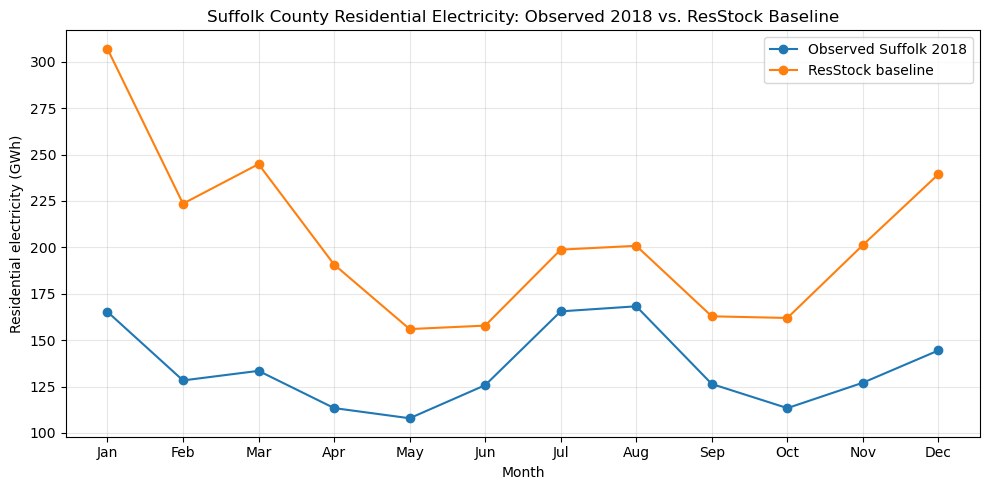

In [46]:
import matplotlib.pyplot as plt

months = ["Jan","Feb","Mar","Apr","May","Jun",
          "Jul","Aug","Sep","Oct","Nov","Dec"]

observed_monthly_gwh = [
    165.28, 128.31, 133.47, 113.42,
    107.94, 125.76, 165.52, 168.24,
    126.39, 113.40, 127.09, 144.47
]

resstock_monthly_gwh = [
    306.95, 223.53, 244.83, 190.74,
    155.98, 157.84, 198.77, 200.83,
    162.85, 161.96, 201.25, 239.41
]

plt.figure(figsize=(10,5))

plt.plot(
    months,
    observed_monthly_gwh,
    marker="o",
    label="Observed Suffolk 2018"
)

plt.plot(
    months,
    resstock_monthly_gwh,
    marker="o",
    label="ResStock baseline"
)

plt.xlabel("Month")
plt.ylabel("Residential electricity (GWh)")
plt.title(
    "Suffolk County Residential Electricity: "
    "Observed 2018 vs. ResStock Baseline"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "suffolk_observed_vs_resstock_monthly.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [1]:
# All heating system categories
print(meta["in.hvac_heating_type"].value_counts(dropna=False))

print("\nHeating type + fuel:")
print(meta["in.hvac_heating_type_and_fuel"].value_counts(dropna=False))

print("\nRECS building type:")
print(meta["in.geometry_building_type_recs"].value_counts(dropna=False))

NameError: name 'meta' is not defined